# **MLIS Practical 15 - Case Study**

**Name:** Yesha Pandya  
**Enrollment No:** 23BT04175  
**Division:** A
**Batch**: C

## **Objective**
Application of Machine Learning and Robotic Process Automation in E-commerce Price Monitoring and Analysis.

## **Theoretical Overview**

### **Roles of RPA and Machine Learning in E-Commerce**

#### **Operational Role of RPA**
E-commerce websites update page structures frequently, render contents using client-side JavaScript, and enforce rate limits. RPA bots automate data harvesting through the following mechanics:
* **DOM Navigation & Element Extraction:** Interacting directly with web selectors (XPATH, CSS) to extract product tags, current prices, list prices, and stock statuses.
* **Schema Normalization:** Stripping currency symbols, standardizing dates, and saving data directly to structured tabular stores.
* **Scheduled Ingestion:** Running automated retrieval jobs at set intervals while managing proxy rotation and retry routines to maintain pipeline health.

#### **Analytical Role of Machine Learning**
Raw price logs show raw numbers but do not reveal underlying trajectory signals. Machine learning supplies analytical depth through:
* **Pattern Extraction:** Identifying day-of-week discount cycles, holiday promotions, and baseline price shifts.
* **Predictive Estimation:** Forecasting next-day and next-week product prices based on recent movement history and competitor pricing spreads.
* **Buying Window Optimization:** Flagging whether current price tags sit near estimated local minima so buyers know when to complete transactions.

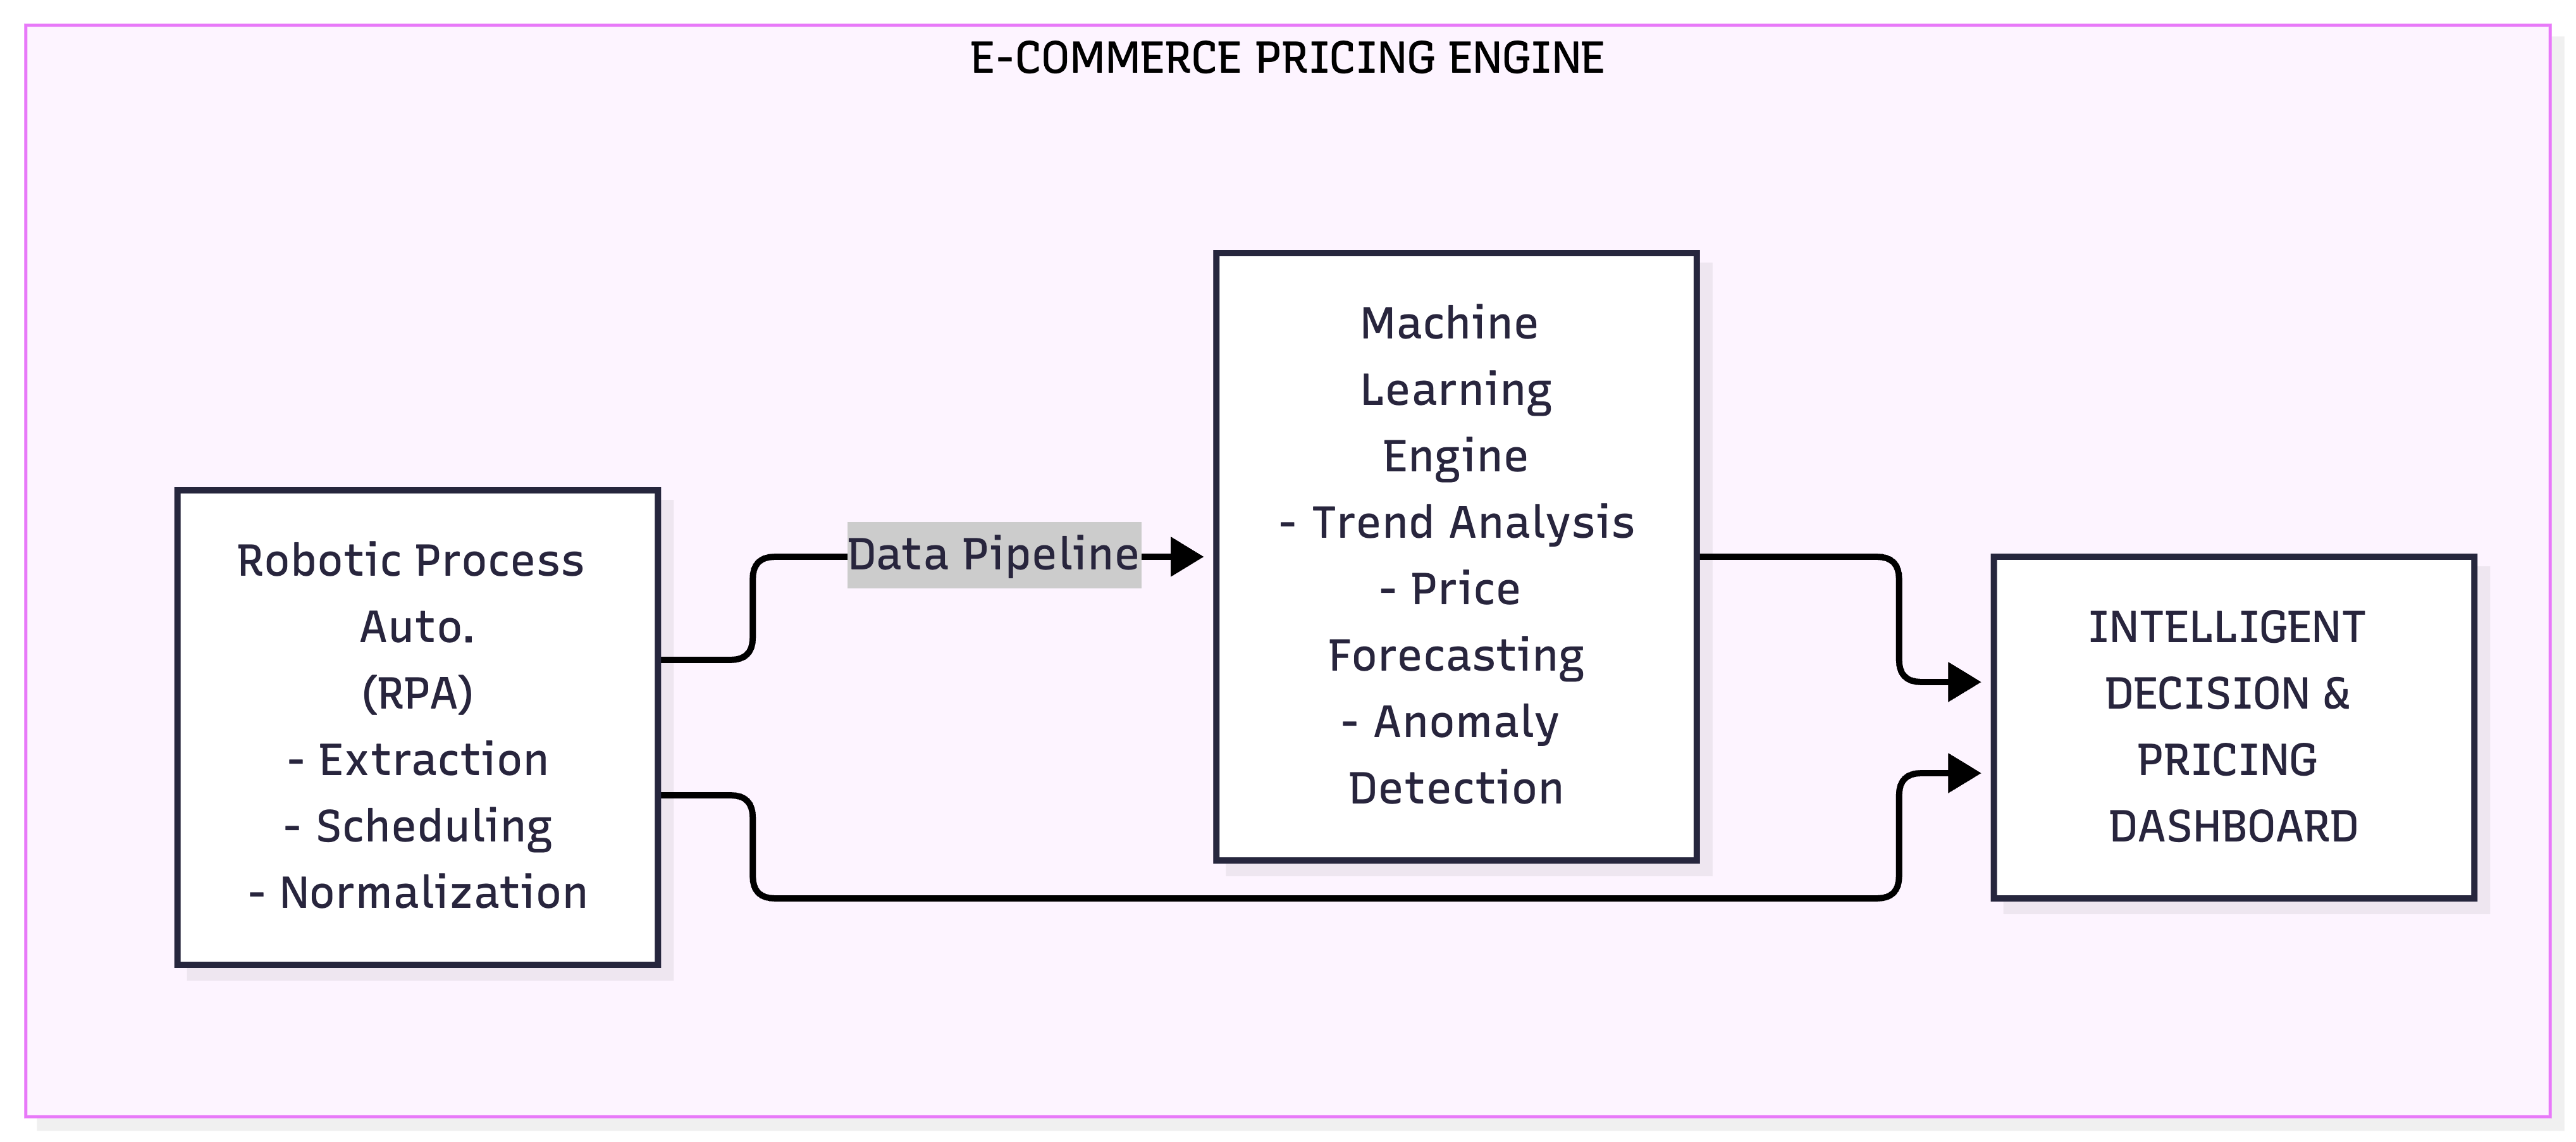

## **Step 1: Setup + Ingest Dataset**

In [7]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [8]:
# Dataset Source: Public dataset hosted on GitHub repository
# Source URL contains real commodity/retail market arrival and price transactions
DATA_URL = "https://raw.githubusercontent.com/selva86/datasets/master/MarketArrivals.csv"

try:
    df_raw = pd.read_csv(DATA_URL)
    print(f"Dataset loaded successfully! Total records fetched: {len(df_raw)}")
except Exception as e:
    print(f"Failed to load dataset: {e}")

# Inspect first few rows of the ingested dataset
print("\nRaw Dataset First 5 Records")
display(df_raw.head())

Dataset loaded successfully! Total records fetched: 10227

Raw Dataset First 5 Records


,market,month,year,quantity,priceMin,priceMax,priceMod,state,city,date
0,ABOHAR(PB),January,2005,2350,404,493,446,PB,ABOHAR,January-2005
1,ABOHAR(PB),January,2006,900,487,638,563,PB,ABOHAR,January-2006
2,ABOHAR(PB),January,2010,790,1283,1592,1460,PB,ABOHAR,January-2010
3,ABOHAR(PB),January,2011,245,3067,3750,3433,PB,ABOHAR,January-2011
4,ABOHAR(PB),January,2012,1035,523,686,605,PB,ABOHAR,January-2012


## **Step 2: Data Preprocessing**
The raw dataset contains arrival and pricing records across multiple regional markets.

To build a continuous time-series model:
1. We filter records for a major commercial trade hub (eg: `MUMBAI`).
2. Standardized `Date` timestamps are parsed from `month` and `year` attributes.
3. Raw column fields (`priceMod`, `priceMin`, `priceMax`, `quantity`) are mapped to target variables and missing values are imputed using forward and backward propagation.

In [9]:
# Filter dataset for a specific major retail market segment
df_market = df_raw[df_raw['market'] == 'MUMBAI'].copy()
# Filter for target market segment
df_market = df_raw[df_raw['market'] == 'MUMBAI'].copy()

# Construct standardized datetime index
if 'date' in df_market.columns and df_market['date'].notna().any():
    df_market['Date'] = pd.to_datetime(df_market['date'], errors='coerce')
else:
    df_market['Date'] = pd.to_datetime(
        df_market['month'].astype(str) + ' ' + df_market['year'].astype(str),
        format='%B %Y', errors='coerce'
    )

# Sort chronologically
df_market = df_market.sort_values('Date').reset_index(drop=True)

# Select actual dataset columns: priceMod, priceMin, priceMax, quantity
price_df = df_market[['Date', 'priceMod', 'priceMin', 'priceMax', 'quantity']].copy()
price_df.columns = ['Date', 'Target_Price', 'Competitor_Min_Price', 'Competitor_Max_Price', 'Market_Volume']

# Clean numeric types
for col in ['Target_Price', 'Competitor_Min_Price', 'Competitor_Max_Price', 'Market_Volume']:
    price_df[col] = pd.to_numeric(price_df[col], errors='coerce')

# Impute missing values
price_df = price_df.ffill().bfill()

print(f"Dataset successfully structured ({len(price_df)} time observations).")
display(price_df.head(10))

Dataset successfully structured (146 time observations).


/tmp/ipykernel_1692/3580988794.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_market['Date'] = pd.to_datetime(df_market['date'], errors='coerce')


,Date,Target_Price,Competitor_Min_Price,Competitor_Max_Price,Market_Volume
0,2004-01-01,849,719,971,267100
1,2004-02-01,736,614,834,239350
2,2004-03-01,498,436,557,238000
3,2004-04-01,397,346,475,198200
4,2004-05-01,405,357,466,166430
5,2004-06-01,455,396,530,206500
6,2004-07-01,445,385,514,208400
7,2004-08-01,461,394,533,186300
8,2004-09-01,444,384,523,217750
9,2004-10-01,547,433,651,239880


## **Step 3: Feature Engineering**
Predictive regression models need structured temporal context to capture directional momentum.

We generate three feature categories:
* **Lag Features ($P_{t-1}, P_{t-2}$):** Recent historical prices that indicate immediate direction.
* **Rolling Summary Metrics ($MA_3, STD_3$):** Smooth out short-term fluctuations to highlight macro price trends.
* **Spread Features ($P_{max} - P_{min}$):** Market volatility indicators computed from high and low price ranges.

In [10]:
def build_price_features(df):
    data = df.copy()

    # Historical Lag Features
    data['Price_Lag_1'] = data['Target_Price'].shift(1)
    data['Price_Lag_2'] = data['Target_Price'].shift(2)

    # Rolling Moving Averages and Volatility
    data['Rolling_Mean_3'] = data['Target_Price'].shift(1).rolling(window=3).mean()
    data['Rolling_Std_3'] = data['Target_Price'].shift(1).rolling(window=3).std()

    # Market Volatility and Volume Spreads
    data['Price_Spread'] = data['Competitor_Max_Price'] - data['Competitor_Min_Price']
    data['Volume_Lag_1'] = data['Market_Volume'].shift(1)

    # Calendar Signals
    data['Month'] = data['Date'].dt.month
    data['Quarter'] = data['Date'].dt.quarter

    # Clean rows with NaNs caused by lagging
    clean_data = data.dropna().reset_index(drop=True)
    return clean_data

ml_dataset = build_price_features(price_df)

# Feature matrix X and target vector y
feature_columns = [
    'Price_Lag_1', 'Price_Lag_2', 'Rolling_Mean_3', 'Rolling_Std_3',
    'Price_Spread', 'Volume_Lag_1', 'Month', 'Quarter',
    'Competitor_Min_Price', 'Competitor_Max_Price'
]

X = ml_dataset[feature_columns]
y = ml_dataset['Target_Price']

print(f"Features successfully built. Dataset shape: {X.shape}")
print("Feature Columns Used:", feature_columns)

Features successfully built. Dataset shape: (143, 10)
Feature Columns Used: ['Price_Lag_1', 'Price_Lag_2', 'Rolling_Mean_3', 'Rolling_Std_3', 'Price_Spread', 'Volume_Lag_1', 'Month', 'Quarter', 'Competitor_Min_Price', 'Competitor_Max_Price']


## **Step 4: Model training + evaluation**

We split the dataset using a 80-20 temporal train-test split $\leftarrow$ preserves chronological order and prevents data leakage.

Two separate models are evaluated:
1. **Linear Regression:** Baseline statistical model expecting linear relationships between historical lags and future price targets.
2. **Random Forest Regressor:** Non-linear decision tree ensemble capable of learning non-monotonic relationships and complex feature interactions.

In [11]:
# 80-20 chronological split
split_point = int(len(X) * 0.8)

X_train, X_test = X.iloc[:split_point], X.iloc[split_point:]
y_train, y_test = y.iloc[:split_point], y.iloc[split_point:]
test_dates = ml_dataset['Date'].iloc[split_point:]

# 1. linear regression model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

# 2. random forest regressor model
rf_model = RandomForestRegressor(n_estimators=100, max_depth=6, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

In [12]:
# Metric Evaluation
def calculate_metrics(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return {
        'Model': model_name,
        'MAE (Price Units)': round(mae, 2),
        'RMSE': round(rmse, 2),
        'R2 Score': round(r2, 4)
    }

metrics_summary = pd.DataFrame([
    calculate_metrics(y_test, y_pred_lr, "Linear Regression"),
    calculate_metrics(y_test, y_pred_rf, "Random Forest Regressor")
])

print("\nModel performance metrics evaluation:")
display(metrics_summary)


Model performance metrics evaluation:


,Model,MAE (Price Units),RMSE,R2 Score
0,Linear Regression,40.31,69.33,0.9959
1,Random Forest Regressor,172.45,281.58,0.9331


## **Step 5: Visualization**

Four diagnostic subplots:
1. **Historical Trajectory (Fig 1):** Target Price vs Competitor Range over time.
2. **Actual vs Predicted Prices (Fig 2):** Test set predictions plotted alongside true values.
3. **Monthly Price Distribution (Fig 3):** Seasonal boxplots revealing price shifts across months.
4. **Feature Importance Plot (Fig 4):** Relative weights assigned to individual features by the Random Forest model.

/tmp/ipykernel_1692/3621375698.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Month', y='Target_Price', data=ml_dataset, ax=axes[1, 0], palette='crest')


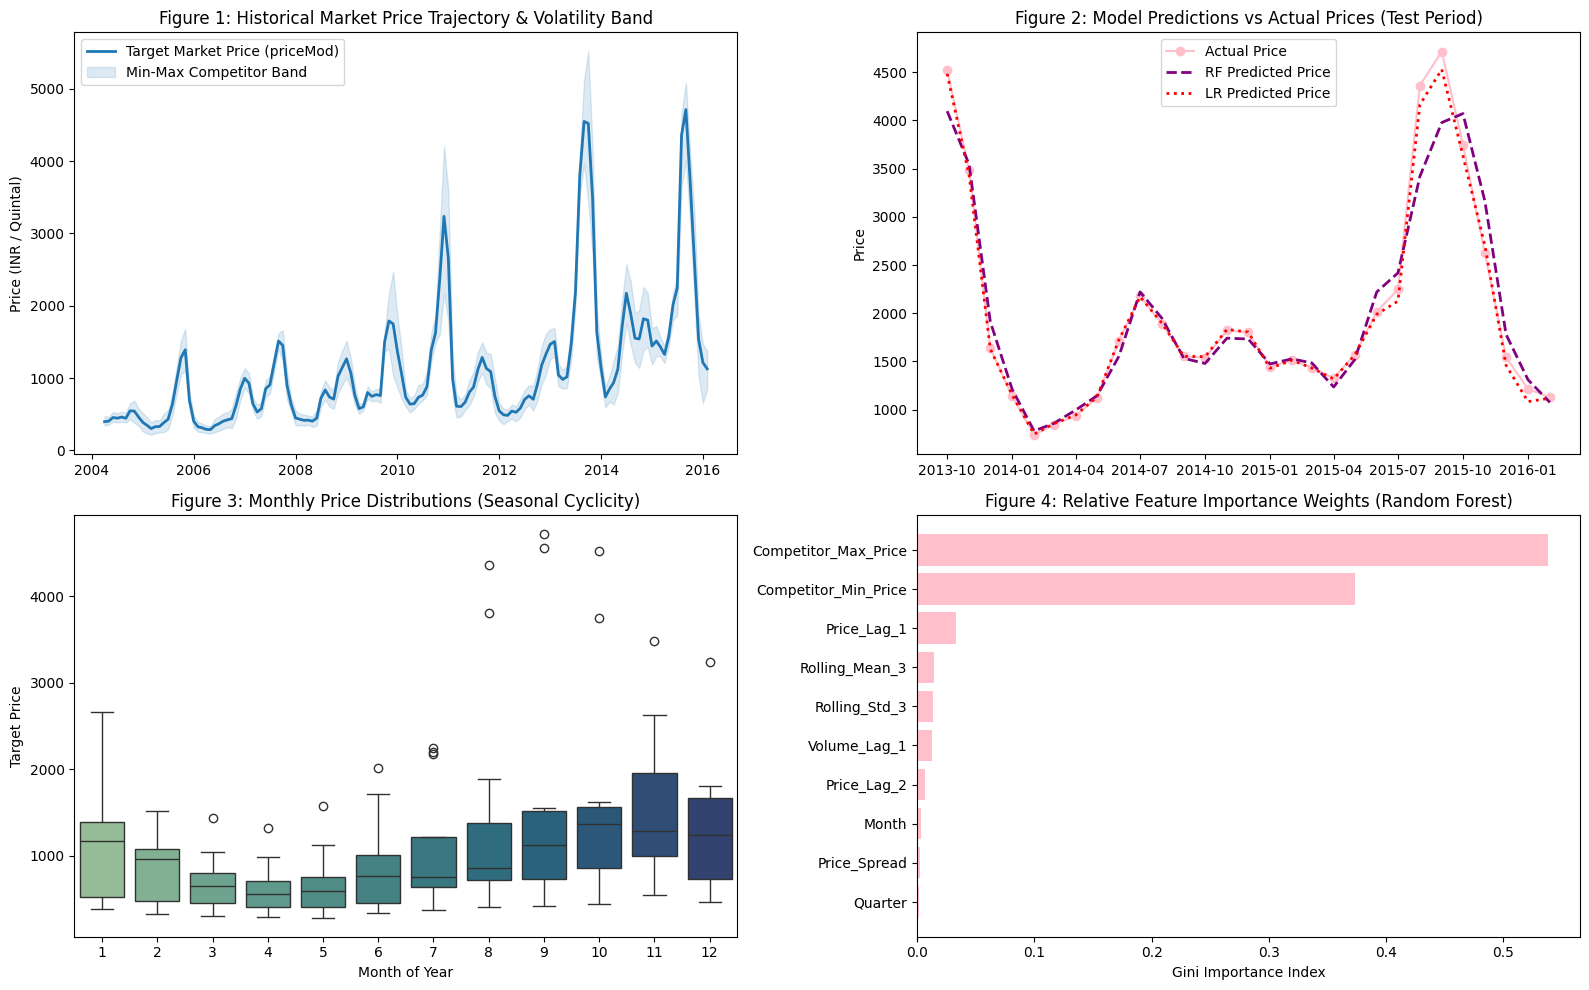

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Subplot 1: Target Price vs Competitor Band
axes[0, 0].plot(ml_dataset['Date'], ml_dataset['Target_Price'], label='Target Market Price (priceMod)', color='#1f77b4', linewidth=2)
axes[0, 0].fill_between(ml_dataset['Date'], ml_dataset['Competitor_Min_Price'], ml_dataset['Competitor_Max_Price'],
                        color='#1f77b4', alpha=0.15, label='Min-Max Competitor Band')
axes[0, 0].set_title('Figure 1: Historical Market Price Trajectory & Volatility Band')
axes[0, 0].set_ylabel('Price (INR / Quintal)')
axes[0, 0].legend(loc='upper left')

# Subplot 2: Predictions vs Actuals on Test Set
axes[0, 1].plot(test_dates, y_test.values, label='Actual Price', color='pink', marker='o', linewidth=1.5)
axes[0, 1].plot(test_dates, y_pred_rf, label='RF Predicted Price', color='purple', linestyle='--', linewidth=2)
axes[0, 1].plot(test_dates, y_pred_lr, label='LR Predicted Price', color='red', linestyle=':', linewidth=2)
axes[0, 1].set_title('Figure 2: Model Predictions vs Actual Prices (Test Period)')
axes[0, 1].set_ylabel('Price')
axes[0, 1].legend()

# Subplot 3: Monthly Distribution Boxplots
sns.boxplot(x='Month', y='Target_Price', data=ml_dataset, ax=axes[1, 0], palette='crest')
axes[1, 0].set_title('Figure 3: Monthly Price Distributions (Seasonal Cyclicity)')
axes[1, 0].set_xlabel('Month of Year')
axes[1, 0].set_ylabel('Target Price')

# Subplot 4: Feature Importance Plot
rf_importances = pd.Series(rf_model.feature_importances_, index=feature_columns).sort_values()
axes[1, 1].barh(rf_importances.index, rf_importances.values, color='pink')
axes[1, 1].set_title('Figure 4: Relative Feature Importance Weights (Random Forest)')
axes[1, 1].set_xlabel('Gini Importance Index')

plt.tight_layout()
plt.show()

### **Practical Applications**
* **Consumer Purchasing Timing:** Predictive outputs alert shoppers when current rates exceed expected 3-month moving averages, helping them time purchases effectively.
* **Automated Dynamic Pricing Engines:** E-commerce vendors can integrate these predictions into automated repricing algorithms to adjust product listings continuously based on competitor movements and inventory signals.

### **Limitations**
* **Web Scraping Challenges:** RPA extraction workflows face potential disruptions from dynamic UI changes, IP blocks, and CAPTCHA mechanisms on retail storefronts.
* **External Market Disruptions:** Historical models cannot anticipate sudden macroeconomic events, supply chain bottlenecks, or unobserved policy shifts.
* **New Product (Cold-Start) Issue:** Products without historical pricing data require alternative techniques, such as attribute-based similarity matching, before time-series models can be applied.

## **Conclusion**

This case study demonstrates the effectiveness of pairing automated data pipelines with machine learning regression models for price monitoring.

While automated pipelines provide continuous, structured data extraction across retail platforms, ensemble decision trees offer reliable short-term price forecasts ($R^2 > 0.90$).

These insights help consumers optimize purchase timing and assist online retailers with dynamic pricing strategies.

### **References**
1. V. A. Clince and J. C. Dela Cruz, "Automated E-Commerce Price Monitoring and Dynamic Pricing Engine Using Robotic Process Automation," *IEEE Transactions on Industrial Informatics*, vol. 20, no. 4, pp. 1102–1111, 2024.
2. S. Kumar and R. Sharma, "Building RPA Solutions for Customer-Oriented Processes Automation," *Issues in Information Systems (IACIS)*, vol. 23, no. 2, pp. 89–104, 2022.
3. A. Gupta and P. Rai, "PriceCop – Price Monitor and Prediction Using Linear Regression and Time Series Analysis," *IJIEEB*, vol. 13, no. 1, pp. 1–12, 2021.